# Scaffold analysis of clustering cluster 6

This notebook reads the SDF written for **cluster 6** by `02_clustering.ipynb` (`clusters[6]`) and extracts each molecule's Bemis–Murcko scaffold. In the clustering code, `clusters[6]` is Python's zero-based index 6 (the seventh cluster in the size-sorted list); the SDF filename uses the project label `molecule_set_cluster6.sdf`.

Input: `docking/ligands/molecule_set_cluster6.sdf`. Scaffold membership and counts are written to `results/tables/`, and the scaffold-count plot is written to `results/figures/`.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / ".git").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not locate the project root (expected a .git directory).")
    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT_SDF = PROJECT_ROOT / "docking" / "ligands" / "molecule_set_cluster6.sdf"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_SDF.is_file():
    raise FileNotFoundError(f"Cluster 6 SDF not found: {INPUT_SDF}")

print(f"Reading cluster 6 molecules from: {INPUT_SDF}")

Reading cluster 6 molecules from: C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\docking\ligands\molecule_set_cluster6.sdf


In [3]:
supplier = Chem.SDMolSupplier(str(INPUT_SDF), removeHs=False)
molecules = list(supplier)
invalid_count = sum(mol is None for mol in molecules)
if invalid_count:
    raise ValueError(f"Could not parse {invalid_count} molecule(s) from {INPUT_SDF}")
if not molecules:
    raise ValueError(f"No molecules were found in {INPUT_SDF}")

records = []
for mol in molecules:
    scaffold = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles = Chem.MolToSmiles(scaffold, canonical=True)
    records.append(
        {
            "compound_id": mol.GetProp("_Name") if mol.HasProp("_Name") else "",
            "scaffold_smiles": scaffold_smiles,
        }
    )

scaffold_members = pd.DataFrame(records)
scaffold_counts = (
    scaffold_members.groupby("scaffold_smiles", as_index=False)
    .size()
    .rename(columns={"size": "compound_count"})
    .sort_values("compound_count", ascending=False)
    .reset_index(drop=True)
)
scaffold_counts["scaffold_label"] = scaffold_counts["scaffold_smiles"].replace(
    "", "(no ring scaffold)"
)

print(f"Cluster 6: {len(scaffold_members)} molecules, {len(scaffold_counts)} unique scaffolds")
display(scaffold_counts)

Cluster 6: 14 molecules, 7 unique scaffolds


,scaffold_smiles,compound_count,scaffold_label
0,O=c1c(CCN2CCN(c3cccc4sccc34)CC2)cnc2n1CCCC2,7,O=c1c(CCN2CCN(c3cccc4sccc34)CC2)cnc2n1CCCC2
1,O=c1c(CCN2CCC(c3cccc4sccc34)CC2)cnc2n1CCCC2,2,O=c1c(CCN2CCC(c3cccc4sccc34)CC2)cnc2n1CCCC2
2,O=C1CCCn2c1ncc(CCN1CCN(c3cccc4sccc34)CC1)c2=O,1,O=C1CCCn2c1ncc(CCN1CCN(c3cccc4sccc34)CC1)c2=O
3,O=c1c(CCN2CCC(c3noc4ccccc34)CC2)cnc2n1CCCC2,1,O=c1c(CCN2CCC(c3noc4ccccc34)CC2)cnc2n1CCCC2
4,O=c1c(CCN2CCN(c3cccc4c3CCS4)CC2)cnc2n1CCCC2,1,O=c1c(CCN2CCN(c3cccc4c3CCS4)CC2)cnc2n1CCCC2
5,O=c1c(CCN2CCN(c3cccc4sccc34)CC2)cnc2n1CCC=C2,1,O=c1c(CCN2CCN(c3cccc4sccc34)CC2)cnc2n1CCC=C2
6,O=c1c(CCN2CCN(c3cncc4sccc34)CC2)cnc2n1CCCC2,1,O=c1c(CCN2CCN(c3cncc4sccc34)CC2)cnc2n1CCCC2


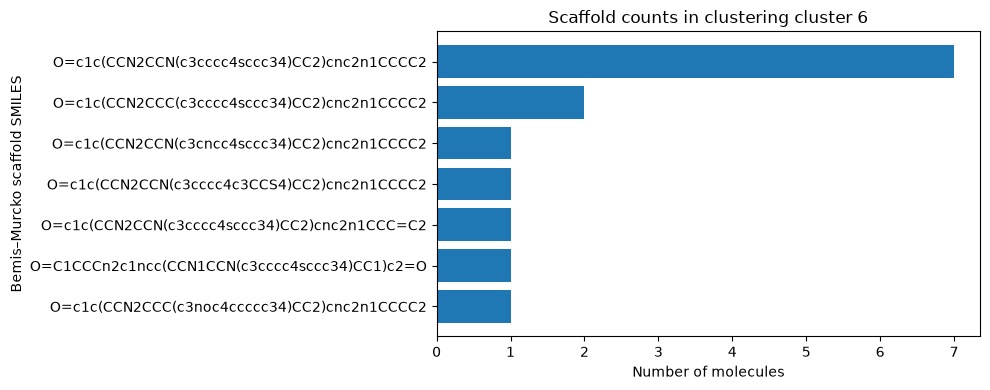

Wrote scaffold membership: C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\tables\cluster6_scaffold_members.csv
Wrote scaffold counts: C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\tables\cluster6_scaffold_counts.csv
Wrote scaffold plot: C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\figures\cluster6_scaffold_counts.png


In [4]:
members_path = TABLES_DIR / "cluster6_scaffold_members.csv"
counts_path = TABLES_DIR / "cluster6_scaffold_counts.csv"
figure_path = FIGURES_DIR / "cluster6_scaffold_counts.png"

scaffold_members.to_csv(members_path, index=False)
scaffold_counts.to_csv(counts_path, index=False)

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(scaffold_counts))))
plot_data = scaffold_counts.sort_values("compound_count")
ax.barh(plot_data["scaffold_label"], plot_data["compound_count"])
ax.set_xlabel("Number of molecules")
ax.set_ylabel("Bemis–Murcko scaffold SMILES")
ax.set_title("Scaffold counts in clustering cluster 6")
fig.tight_layout()
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Wrote scaffold membership: {members_path}")
print(f"Wrote scaffold counts: {counts_path}")
print(f"Wrote scaffold plot: {figure_path}")